# Mork-2 training data

Looks at the pretrain mix written by `mork-prepare`: Python-Edu, Cosmopedia v2, and FineWeb-Edu dedup, tokenized with a byte-level BPE and stored as `corpus_{split}_XXXX.npy` shards. Documents in a shard are separated by `<|end|>`.

In [1]:
from __future__ import annotations

import json
import sys
from pathlib import Path

%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np

ROOT = Path("..").resolve()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from mork.tokenizer import MorkTokenizer, SPECIAL_TOKENS

DATA = ROOT / "data"
RAW = DATA / "raw"
SOURCES = ("python", "cosmopedia", "fineweb")
manifest = json.loads((DATA / "manifest.json").read_text())
tokenizer = MorkTokenizer.load(DATA / "tokenizer.json")
END_ID = tokenizer.special_token_id("<|end|>")
print(f"vocab {tokenizer.vocab_size:,}   <|end|> id {END_ID}")
print(f"manifest complete: {manifest['complete']}")

vocab 16,384   <|end|> id 2
manifest complete: True


## Mix

The prepare step targets 3 GB Python, 3 GB Cosmopedia, and 2 GB FineWeb, with 1% of each held out. `text_bytes` counts characters after download, before tokenization.

source       split        text       docs    chars/doc
python       train     2.97 GB    362,011        8,204
python       val       0.03 GB      3,678        8,157
cosmopedia   train     2.97 GB    790,891        3,755
cosmopedia   val       0.03 GB      8,033        3,735
fineweb      train     1.98 GB    431,719        4,586
fineweb      val       0.02 GB      4,296        4,663

train: 1,995,020,916 tokens in 100 shard(s)
val: 20,240,965 tokens in 2 shard(s)
train chars/token: 3.97


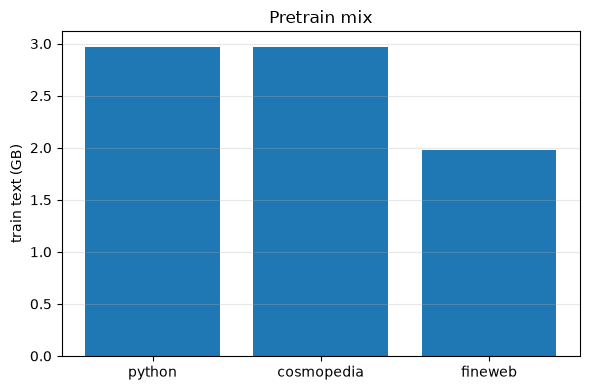

In [2]:
def gb(n: int) -> str:
    return f"{n / 1e9:.2f} GB"

print(f"{'source':<12} {'split':<6} {'text':>10} {'docs':>10} {'chars/doc':>12}")
train_bytes = []
for name in SOURCES:
    for split in ("train", "val"):
        stats = manifest["sources"][name][split]
        chars = stats["text_bytes"]
        docs = stats["docs"]
        print(
            f"{name:<12} {split:<6} {gb(chars):>10} {docs:>10,} {chars / docs:>12,.0f}"
        )
        if split == "train":
            train_bytes.append(chars)

print()
for split in ("train", "val"):
    tokens = manifest["tokens"][split]
    shards = manifest["shards"][split]
    print(f"{split}: {tokens:,} tokens in {shards} shard(s)")

train_chars = sum(manifest["sources"][name]["train"]["text_bytes"] for name in SOURCES)
print(f"train chars/token: {train_chars / manifest['tokens']['train']:.2f}")

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(SOURCES, [n / 1e9 for n in train_bytes])
ax.set(ylabel="train text (GB)", title="Pretrain mix")
ax.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## Shards

Each training shard holds 20 million token ids except the last, which keeps the remainder. The loader reads `*_{split}_*.npy`.

train: 100 files, 1,995,020,916 tokens, min 15,020,916, max 20,000,000
val: 2 files, 20,240,965 tokens, min 240,965, max 20,000,000

corpus_train_0000.npy: 16,283 / 16,384 vocab ids appear (99.4%)
  <|user|> id 0: 0 hits
  <|assistant|> id 1: 0 hits
  <|end|> id 2: 15,976 hits
  <|pad|> id 3: 0 hits


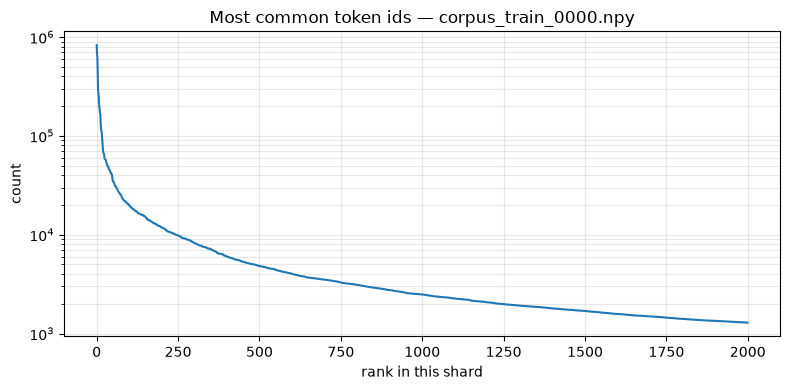

In [3]:
for split in ("train", "val"):
    paths = sorted(DATA.glob(f"corpus_{split}_*.npy"))
    sizes = [int(np.load(path, mmap_mode="r").shape[0]) for path in paths]
    print(
        f"{split}: {len(paths)} files, {sum(sizes):,} tokens, "
        f"min {min(sizes):,}, max {max(sizes):,}"
    )

train_paths = sorted(DATA.glob("corpus_train_*.npy"))
sample = np.load(train_paths[0], mmap_mode="r")
counts = np.bincount(sample, minlength=tokenizer.vocab_size)
used = int((counts > 0).sum())
print(
    f"\n{train_paths[0].name}: {used:,} / {tokenizer.vocab_size:,} "
    f"vocab ids appear ({used / tokenizer.vocab_size:.1%})"
)
for name in SPECIAL_TOKENS:
    token_id = tokenizer.special_token_id(name)
    print(f"  {name} id {token_id}: {int(counts[token_id]):,} hits")

order = np.argsort(counts)[::-1]
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(counts[order[:2000]])
ax.set(
    xlabel="rank in this shard",
    ylabel="count",
    yscale="log",
    title=f"Most common token ids — {train_paths[0].name}",
)
ax.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.show()

## Document lengths

One pass over each raw JSONL. The sample used for tokens-per-document is a reservoir of 200 documents, so it is not only the start of the file.

scanned python: 362,011 docs
scanned cosmopedia: 790,891 docs
scanned fineweb: 431,719 docs


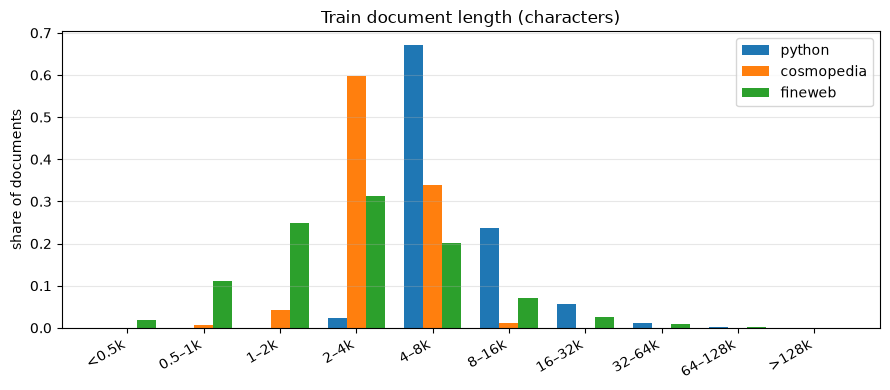


source           docs  chars/doc   tokens/doc  chars/token
python            200      8,232        2,535         3.25
cosmopedia        200      3,937          830         4.75
fineweb           200      3,922          941         4.17


In [4]:
EDGES = np.array([0, 500, 1_000, 2_000, 4_000, 8_000, 16_000, 32_000, 64_000, 128_000, 10**9])
LABELS = [
    "<0.5k",
    "0.5–1k",
    "1–2k",
    "2–4k",
    "4–8k",
    "8–16k",
    "16–32k",
    "32–64k",
    "64–128k",
    ">128k",
]


def scan_source(name: str, n_encode: int = 200, n_show: int = 1):
    path = RAW / f"{name}_train.jsonl"
    rng = np.random.default_rng(1337)
    hist = np.zeros(len(EDGES) - 1, dtype=np.int64)
    encode_sample: list[str] = []
    shown: list[str] = []
    seen = 0
    with path.open(encoding="utf-8") as handle:
        for line in handle:
            if not line.strip():
                continue
            text = json.loads(line)["text"]
            seen += 1
            bin_index = int(np.searchsorted(EDGES, len(text), side="right") - 1)
            hist[min(bin_index, len(hist) - 1)] += 1
            if len(shown) < n_show and seen == 1_000:
                shown.append(text)
            if len(encode_sample) < n_encode:
                encode_sample.append(text)
            else:
                pick = int(rng.integers(0, seen))
                if pick < n_encode:
                    encode_sample[pick] = text
    return hist, encode_sample, shown


hists = {}
samples = {}
previews = {}
for name in SOURCES:
    hists[name], samples[name], previews[name] = scan_source(name)
    print(f"scanned {name}: {int(hists[name].sum()):,} docs")

fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(LABELS))
width = 0.25
for i, name in enumerate(SOURCES):
    share = hists[name] / hists[name].sum()
    ax.bar(x + (i - 1) * width, share, width=width, label=name)
ax.set_xticks(x, LABELS, rotation=30, ha="right")
ax.set(ylabel="share of documents", title="Train document length (characters)")
ax.legend()
ax.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print(f"\n{'source':<12} {'docs':>8} {'chars/doc':>10} {'tokens/doc':>12} {'chars/token':>12}")
for name in SOURCES:
    texts = samples[name]
    char_lengths = np.array([len(text) for text in texts])
    token_lengths = np.array([len(tokenizer.encode(text)) for text in texts])
    print(
        f"{name:<12} {len(texts):>8,} {char_lengths.mean():>10,.0f} "
        f"{token_lengths.mean():>12,.0f} {char_lengths.sum() / token_lengths.sum():>12.2f}"
    )

## Samples

One training document from each source, then one complete document from the middle of the token shards. A shard can start in the middle of a document, so the sample begins after the first `<|end|>`.

In [5]:
def preview(text: str, limit: int = 500) -> str:
    text = text.replace("\r\n", "\n").strip()
    if len(text) <= limit:
        return text
    return text[:limit] + " …"


for name in SOURCES:
    text = previews[name][0] if previews[name] else samples[name][0]
    print(f"\n===== {name} train ({len(text):,} chars) =====")
    print(preview(text))

shard = train_paths[len(train_paths) // 2]
ids = np.load(shard, mmap_mode="r")
ends = np.flatnonzero(ids == END_ID)
# The first <|end|> may finish a document that started in the previous shard.
start = int(ends[0] + 1)
stop = int(ends[1] + 1)
decoded = tokenizer.decode(ids[start:stop].tolist())
print(f"\n===== {shard.name} first complete doc ({stop - start:,} tokens) =====")
print(preview(decoded, 700))


===== python train (4,353 chars) =====
# 1a) Copy and paste the function definition from the markdown file below. This block of code defines a function called hello(). However, you haven't used the
#function yet! In order to do this, you must type out hello() and run your program. Do this below, and comment an observation about what you see.






# 1b) Practice your looping skills! Write a function called hello2 that does the same thing as the original hello function, but replace the body of the function
#(print("Hello World!\n"*10) …

===== cosmopedia train (3,405 chars) =====
Title: My Unforeseen Bake Sale Misadventure: A Tale of Imperfect Cookies and Unexpected Consequences

So there I was, knee-deep in flour and butter, living my best life as an amateur baker. You know, those folks who find solace in whipping up delectable treats for friends and family? That was me. One sunny afternoon, I decided to host a bake sale, offering an array of goodies that would make even Martha Stewar